<a href="https://colab.research.google.com/github/opaiot/ia-otimizacao-iot-industrias-negocios-public/blob/main/M4/colab/M4_Aplicação_Prática_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

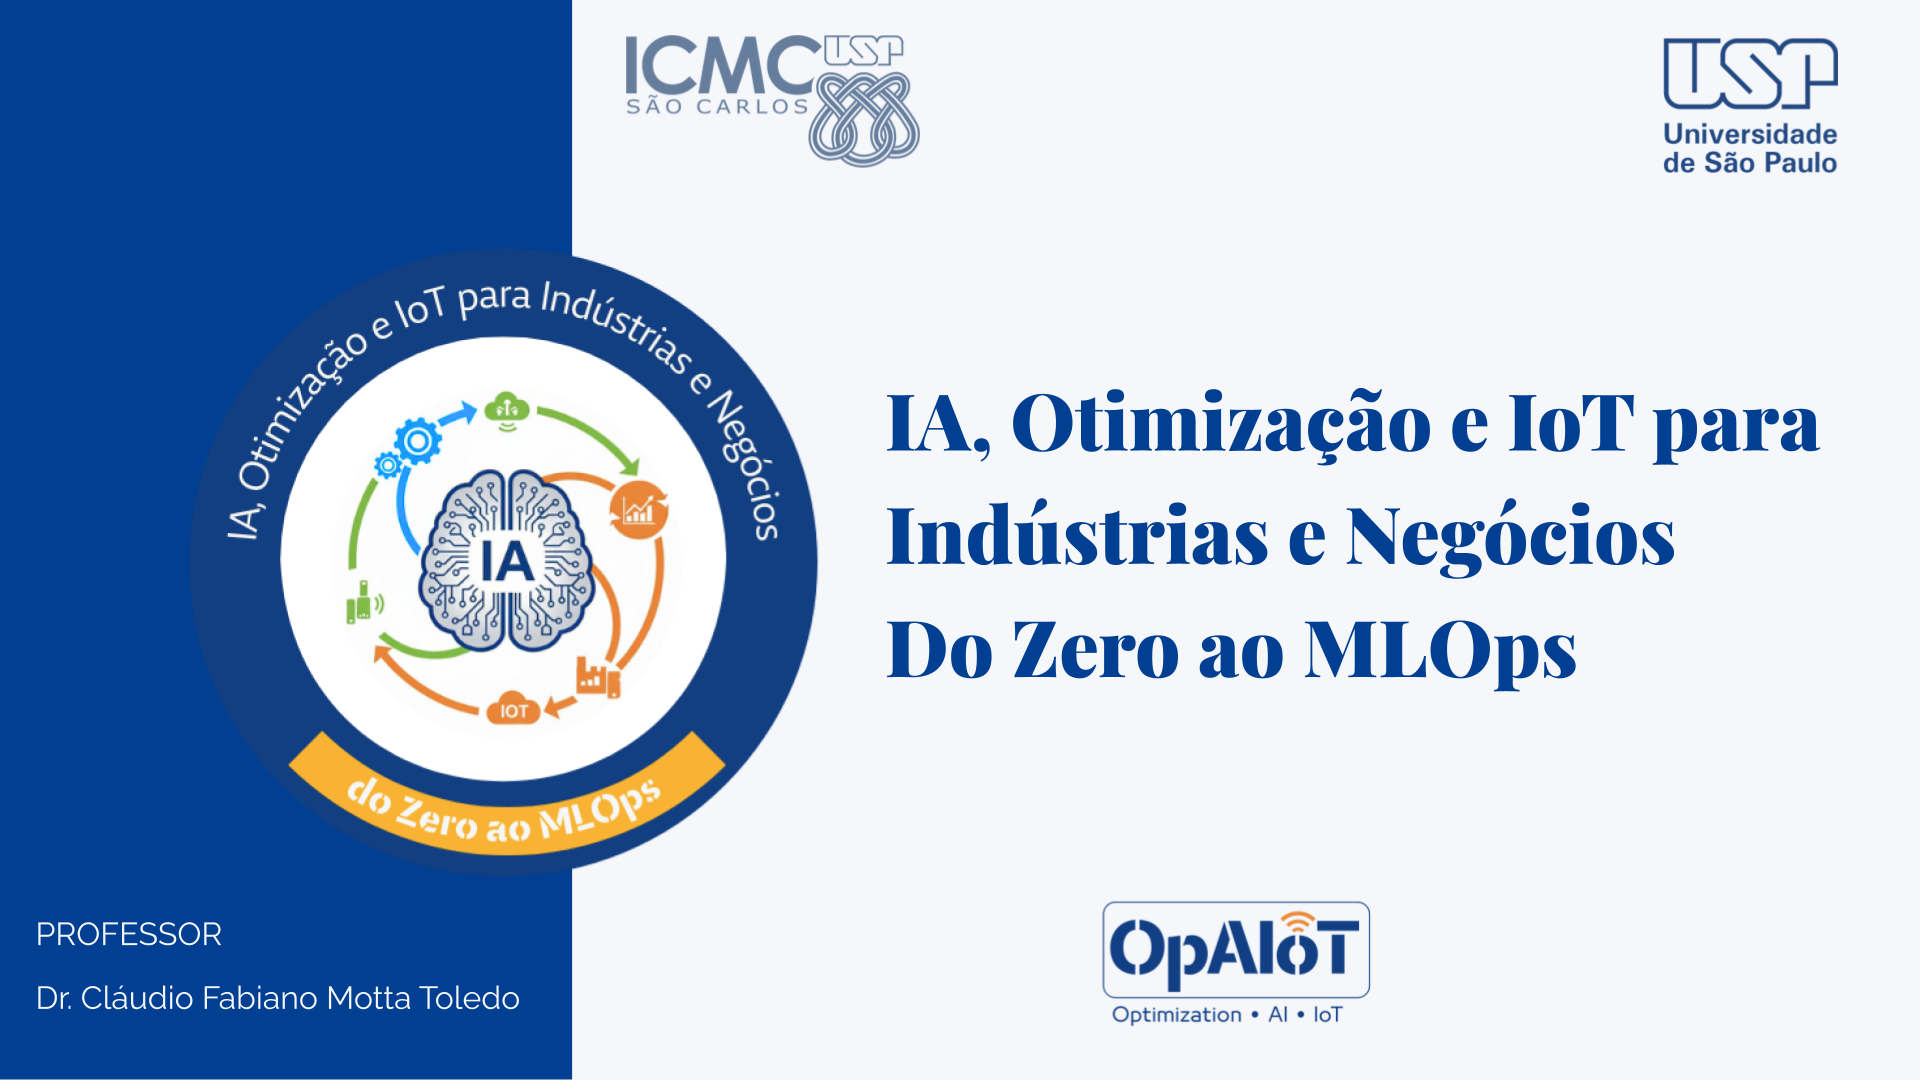

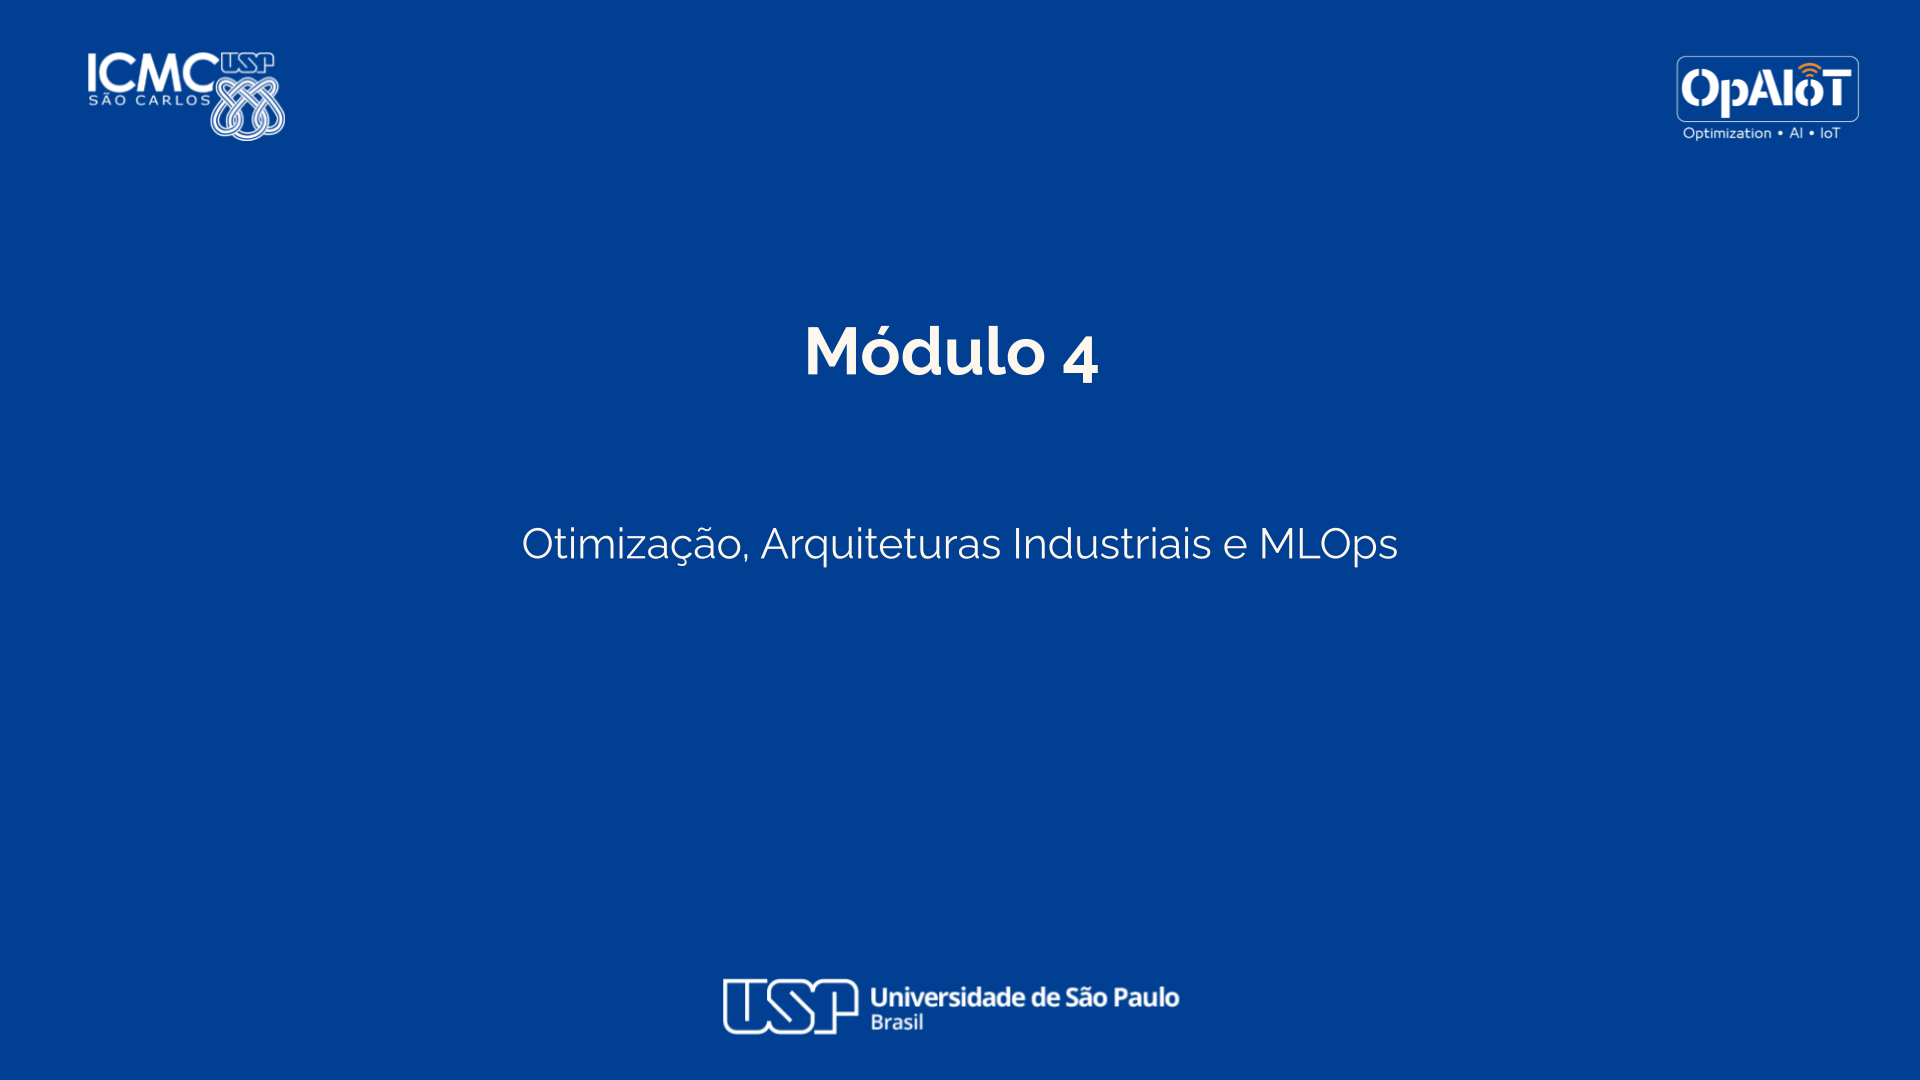

## 1. Objetivos da prática

Ao final deste notebook, você deverá ser capaz de:

1. identificar restrições ativas e restrições com folga;
2. interpretar economicamente os preços-sombra;
3. resolver explicitamente o modelo dual;
4. comparar o valor ótimo primal com o valor ótimo dual;
5. testar alterações nas capacidades dos recursos;
6. testar alterações nos lucros unitários dos produtos;

## 2. Instalação e importação das bibliotecas

Usaremos:

- `pyomo`: biblioteca para modelagem matemática;
- `highspy`: interface Python para o solver HiGHS;
- `pandas`: organização de tabelas;
- `matplotlib`: gráficos simples para visualizar a sensibilidade.

No Google Colab, execute a célula a seguir para instalar as bibliotecas necessárias.


In [ ]:
!pip install -q pyomo highspy pandas matplotlib

import pyomo.environ as pyo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 3. Problema industrial usado na prática

Uma fábrica produz dois produtos:

- Produto A;
- Produto B.

A produção consome três recursos limitados:

- usinagem;
- montagem;
- matéria-prima.

O objetivo é maximizar o lucro total respeitando as capacidades disponíveis.

A formulação primal é:

$$
\max z = 40x_A + 30x_B
$$

sujeito a:

$$
2x_A + x_B \leq 100
$$

$$
x_A + x_B \leq 80
$$

$$
x_A + 3x_B \leq 90
$$

$$
x_A, x_B \geq 0
$$

Em que:

- $x_A$ é a quantidade produzida do Produto A;
- $x_B$ é a quantidade produzida do Produto B.


## 4. Dados do problema

Na célula seguinte, vamos armazenar os dados em dicionários Python.

Essa forma de organizar os dados facilita a construção de modelos indexados em Pyomo, pois podemos acessar os parâmetros por nomes como:

```python
lucro["A"]
capacidade["Usinagem"]
consumo[("Usinagem", "A")]
```

Essa organização também torna o modelo mais fácil de adaptar para novos produtos ou novos recursos.


In [ ]:
produtos = ["A", "B"]

recursos = ["Usinagem", "Montagem", "Materia_prima"]

lucro = {
    "A": 40,
    "B": 30
}

consumo = {
    ("Usinagem", "A"): 2,
    ("Usinagem", "B"): 1,

    ("Montagem", "A"): 1,
    ("Montagem", "B"): 1,

    ("Materia_prima", "A"): 1,
    ("Materia_prima", "B"): 3
}

capacidade = {
    "Usinagem": 100,
    "Montagem": 80,
    "Materia_prima": 90
}


## 5. Visualização dos dados em tabela

Antes de criar o modelo, é útil visualizar os dados em uma tabela.

Essa tabela ajuda a conectar os dados do problema industrial com a formulação matemática:

- cada linha representa um produto;
- cada coluna de recurso mostra quanto o produto consome;
- a coluna de lucro mostra o ganho por unidade produzida.


In [ ]:
tabela_dados = pd.DataFrame({
    "Produto": produtos,
    "Lucro unitário": [lucro[i] for i in produtos],
    "Usinagem": [consumo[("Usinagem", i)] for i in produtos],
    "Montagem": [consumo[("Montagem", i)] for i in produtos],
    "Matéria-prima": [consumo[("Materia_prima", i)] for i in produtos]
})

display(tabela_dados)

tabela_capacidade = pd.DataFrame({
    "Recurso": recursos,
    "Capacidade disponível": [capacidade[r] for r in recursos]
})

display(tabela_capacidade)


# Parte I — Modelo primal em Pyomo

Nesta primeira parte, vamos implementar o modelo primal.

O modelo primal representa diretamente o problema da empresa:

> Quanto produzir de cada produto para maximizar o lucro, respeitando os recursos disponíveis?

Em Pyomo, vamos criar:

- conjuntos: produtos e recursos;
- parâmetros: lucro, consumo e capacidade;
- variáveis de decisão: quantidade produzida;
- função objetivo: lucro total;
- restrições: consumo de cada recurso não pode ultrapassar sua capacidade.


## 6. Construção do modelo primal

A função abaixo cria um modelo Pyomo.

Observe alguns pontos importantes:

1. `m.I` é o conjunto de produtos.
2. `m.R` é o conjunto de recursos.
3. `m.p[i]` é o lucro unitário do produto `i`.
4. `m.a[r, i]` é o consumo do recurso `r` pelo produto `i`.
5. `m.b[r]` é a capacidade disponível do recurso `r`.
6. `m.x[i]` é a variável de decisão: quantidade do produto `i`.

Os parâmetros `m.p` e `m.b` são declarados como `mutable=True`. Isso permite alterar lucros e capacidades depois que o modelo foi criado, o que será útil na análise de sensibilidade.


In [ ]:
def construir_modelo_primal(produtos, recursos, lucro, consumo, capacidade):
    m = pyo.ConcreteModel(name="Primal_mix_producao")

    # Conjuntos
    m.I = pyo.Set(initialize=produtos)
    m.R = pyo.Set(initialize=recursos)

    # Parâmetros
    m.p = pyo.Param(m.I, initialize=lucro, mutable=True)
    m.a = pyo.Param(m.R, m.I, initialize=consumo)
    m.b = pyo.Param(m.R, initialize=capacidade, mutable=True)

    # Variáveis de decisão
    m.x = pyo.Var(m.I, domain=pyo.NonNegativeReals)

    # Função objetivo: maximizar o lucro total
    m.obj = pyo.Objective(
        expr=sum(m.p[i] * m.x[i] for i in m.I),
        sense=pyo.maximize
    )

    # Restrições de capacidade dos recursos
    def regra_capacidade(m, r):
        return sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]

    m.capacidade = pyo.Constraint(m.R, rule=regra_capacidade)

    return m


## 7. Função auxiliar para resolver modelos

A função abaixo resolve um modelo Pyomo usando o solver `appsi_highs`.

O HiGHS é um solver eficiente para problemas lineares. Aqui estamos usando a interface `appsi_highs`, que é uma forma moderna de conectar Pyomo ao HiGHS.

A função também verifica se o solver está disponível antes de tentar resolver o modelo.


In [ ]:
def resolver_modelo(modelo, tee=False):
    solver = pyo.SolverFactory("appsi_highs")

    if not solver.available(exception_flag=False):
        raise RuntimeError(
            "Solver appsi_highs não disponível. "
            "Verifique se pyomo e highspy foram instalados corretamente."
        )

    resultado = solver.solve(modelo, tee=tee)
    return resultado


## 8. Resolvendo o modelo primal

Agora vamos:

1. construir o modelo primal;
2. resolver o modelo;
3. imprimir a solução ótima.

A solução esperada é:

$$
x_A^* = 42
$$

$$
x_B^* = 16
$$

$$
z^* = 2160
$$


In [ ]:
model_p = construir_modelo_primal(
    produtos=produtos,
    recursos=recursos,
    lucro=lucro,
    consumo=consumo,
    capacidade=capacidade
)

resultado_p = resolver_modelo(model_p)

print("Status:", resultado_p.solver.status)
print("Condição de término:", resultado_p.solver.termination_condition)

print("\nSolução ótima:")
for i in model_p.I:
    print(f"x[{i}] = {pyo.value(model_p.x[i]):.2f}")

print("\nLucro ótimo:")
print(f"z* = {pyo.value(model_p.obj):.2f}")


## 9. Folgas das restrições

A folga indica quanto sobra de um recurso na solução ótima.

Para cada recurso:

$$
\text{folga} = \text{capacidade disponível} - \text{uso do recurso}
$$

Se a folga for zero, a restrição está **ativa**. Isso significa que o recurso foi totalmente utilizado.

Se a folga for positiva, a restrição está **com folga**. Isso significa que ainda há capacidade ociosa.


In [ ]:
def tabela_uso_recursos(modelo):
    linhas = []

    for r in modelo.R:
        uso = sum(
            pyo.value(modelo.a[r, i]) * pyo.value(modelo.x[i])
            for i in modelo.I
        )

        capacidade_r = pyo.value(modelo.b[r])
        folga = capacidade_r - uso

        status = "Ativa" if abs(folga) < 1e-6 else "Com folga"

        linhas.append({
            "Recurso": r,
            "Capacidade disponível": capacidade_r,
            "Uso na solução ótima": uso,
            "Folga": folga,
            "Status": status
        })

    return pd.DataFrame(linhas)

tabela_recursos = tabela_uso_recursos(model_p)
display(tabela_recursos)


## 10. Interpretação inicial das folgas

Observe a tabela anterior:

- usinagem é totalmente utilizada;
- montagem possui capacidade ociosa;
- matéria-prima é totalmente utilizada.

Isso sugere que usinagem e matéria-prima são recursos mais críticos no plano ótimo atual.

A seguir, vamos resolver o modelo dual para calcular o **preço-sombra** de cada recurso.


# Parte II — Modelo dual explícito em Pyomo

O modelo dual fornece uma interpretação econômica do problema primal.

Enquanto o primal responde:

> Quanto produzir de cada produto?

O dual responde:

> Quanto vale cada recurso disponível?

Neste problema, as variáveis duais representam os preços-sombra dos recursos:

- $y_1$: preço-sombra da usinagem;
- $y_2$: preço-sombra da montagem;
- $y_3$: preço-sombra da matéria-prima.

Lembrando que a formulação primal é:

$$
\max z = 40x_A + 30x_B
$$

sujeito a:

$$
2x_A + x_B \leq 100
$$

$$
x_A + x_B \leq 80
$$

$$
x_A + 3x_B \leq 90
$$

$$
x_A, x_B \geq 0
$$


O modelo dual será:

$$
\min w = 100y_1 + 80y_2 + 90y_3
$$

sujeito a:

$$
2y_1 + y_2 + y_3 \geq 40
$$

$$
y_1 + y_2 + 3y_3 \geq 30
$$

$$
y_1,y_2,y_3 \geq 0
$$


## 11. Construção do modelo dual

Na célula seguinte, vamos criar explicitamente o modelo dual em Pyomo.

A variável `d.y[r]` representa o preço-sombra do recurso `r`.

A função objetivo dual minimiza o valor total imputado aos recursos disponíveis.

Cada restrição dual garante que o valor dos recursos consumidos por um produto seja suficiente para cobrir o lucro unitário desse produto.


In [ ]:
def construir_modelo_dual(produtos, recursos, lucro, consumo, capacidade):
    d = pyo.ConcreteModel(name="Dual_mix_producao")

    # Conjuntos
    d.I = pyo.Set(initialize=produtos)
    d.R = pyo.Set(initialize=recursos)

    # Parâmetros
    d.p_lucro = pyo.Param(d.I, initialize=lucro)
    d.a = pyo.Param(d.R, d.I, initialize=consumo)
    d.b = pyo.Param(d.R, initialize=capacidade)

    # Variáveis duais: preços-sombra dos recursos
    d.y = pyo.Var(d.R, domain=pyo.NonNegativeReals)

    # Função objetivo dual
    d.obj = pyo.Objective(
        expr=sum(d.b[r] * d.y[r] for r in d.R),
        sense=pyo.minimize
    )

    # Restrições duais
    def regra_cobertura_lucro(d, i):
        return sum(d.a[r, i] * d.y[r] for r in d.R) >= d.p_lucro[i]

    d.cobertura_lucro = pyo.Constraint(d.I, rule=regra_cobertura_lucro)

    return d


## 12. Resolvendo o modelo dual

Agora vamos resolver o dual e observar os preços-sombra.

O resultado esperado é:

$$
y_{\text{Usinagem}} = 18
$$

$$
y_{\text{Montagem}} = 0
$$

$$
y_{\text{Matéria-prima}} = 4
$$

O valor ótimo dual deve ser igual ao valor ótimo primal:

$$
w^* = z^* = 2160
$$


In [ ]:
model_d = construir_modelo_dual(
    produtos=produtos,
    recursos=recursos,
    lucro=lucro,
    consumo=consumo,
    capacidade=capacidade
)

resultado_d = resolver_modelo(model_d)

print("Status:", resultado_d.solver.status)
print("Condição de término:", resultado_d.solver.termination_condition)

print("\nPreços-sombra obtidos pelo modelo dual:")
for r in model_d.R:
    print(f"y[{r}] = {pyo.value(model_d.y[r]):.2f}")

print("\nValor ótimo dual:")
print(f"w* = {pyo.value(model_d.obj):.2f}")

print("\nComparação primal-dual:")
print(f"z* primal = {pyo.value(model_p.obj):.2f}")
print(f"w* dual   = {pyo.value(model_d.obj):.2f}")


In [ ]:
precos_sombra = {
    r: pyo.value(model_d.y[r])
    for r in model_d.R
}

tabela_interpretacao = tabela_recursos.copy()
tabela_interpretacao["Preço-sombra"] = tabela_interpretacao["Recurso"].map(precos_sombra)

def interpretar_linha(row):
    if row["Status"] == "Ativa" and row["Preço-sombra"] > 1e-6:
        return "Recurso escasso e economicamente valioso"
    elif row["Status"] == "Com folga" and abs(row["Preço-sombra"]) <= 1e-6:
        return "Recurso com sobra; unidade extra não melhora o lucro"
    elif row["Status"] == "Ativa" and abs(row["Preço-sombra"]) <= 1e-6:
        return "Restrição ativa, mas sem valor marginal no ótimo atual"
    else:
        return "Caso a discutir"

tabela_interpretacao["Interpretação"] = tabela_interpretacao.apply(interpretar_linha, axis=1)

display(tabela_interpretacao)


## 13. Tabela integrada: folgas e preços-sombra

Agora vamos juntar as informações do primal e do dual.

O próximo códig cria uma **tabela interpretativa de análise de sensibilidade**, combinando:

1. o **status de cada recurso**: restrição ativa ou com folga;
2. o **preço-sombra** associado a cada recurso;
3. uma **interpretação econômica** do resultado.

---

## 1. Criação do dicionário de preços-sombra

```python
precos_sombra = {
    r: pyo.value(model_d.y[r])
    for r in model_d.R
}
```

Esse trecho cria um dicionário Python chamado `precos_sombra`.

A estrutura geral é:

```python
{
    chave: valor
    for elemento in conjunto
}
```

No seu caso:

```python
r: pyo.value(model_d.y[r])
```

significa:

> para cada recurso `r`, armazene o valor ótimo da variável dual `model_d.y[r]`.

Então, se `model_d.R` contém, por exemplo:

```python
["Horas", "MateriaPrima", "MaoDeObra"]
```

o dicionário pode ficar assim:

```python
{
    "Horas": 12.5,
    "MateriaPrima": 0.0,
    "MaoDeObra": 8.0
}
```

Aqui, `model_d.y[r]` representa a **variável dual associada ao recurso `r`**.

O comando:

```python
pyo.value(model_d.y[r])
```

extrai o valor numérico calculado pelo solver. Sem `pyo.value`, você teria um objeto simbólico do Pyomo, não diretamente um número.

---

## 2. Cópia da tabela original de recursos

```python
tabela_interpretacao = tabela_recursos.copy()
```

Aqui é criada uma cópia da tabela `tabela_recursos`.

Isso é importante porque evita alterar diretamente a tabela original.

Se `tabela_recursos` fosse algo como:

| Recurso      | Uso | Disponível | Folga | Status    |
| ------------ | --: | ---------: | ----: | --------- |
| Horas        | 100 |        100 |     0 | Ativa     |
| MateriaPrima |  70 |         90 |    20 | Com folga |

então `tabela_interpretacao` começa como uma cópia dessa tabela.

---

## 3. Adição da coluna de preço-sombra

```python
tabela_interpretacao["Preço-sombra"] = tabela_interpretacao["Recurso"].map(precos_sombra)
```

Esse comando cria uma nova coluna chamada `"Preço-sombra"`.

A função `.map(precos_sombra)` procura, para cada valor da coluna `"Recurso"`, o preço-sombra correspondente no dicionário `precos_sombra`.

Por exemplo, se:

```python
precos_sombra = {
    "Horas": 12.5,
    "MateriaPrima": 0.0
}
```

e a tabela contém:

| Recurso      |
| ------------ |
| Horas        |
| MateriaPrima |

a nova coluna será:

| Recurso      | Preço-sombra |
| ------------ | -----------: |
| Horas        |         12.5 |
| MateriaPrima |          0.0 |

Ou seja, o código conecta o nome do recurso na tabela com o valor da variável dual obtido no modelo.

---

## 4. Função para interpretar cada linha

```python
def interpretar_linha(row):
```

Essa função recebe uma linha da tabela, chamada aqui de `row`.

Cada `row` contém os dados de um recurso, por exemplo:

```python
row["Recurso"]
row["Status"]
row["Preço-sombra"]
```

A função retorna uma frase explicando a situação econômica daquele recurso.

---

### Caso 1: restrição ativa e preço-sombra positivo

```python
if row["Status"] == "Ativa" and row["Preço-sombra"] > 1e-6:
    return "Recurso escasso e economicamente valioso"
```

Esse caso significa:

* a restrição está **ativa**, ou seja, o recurso foi totalmente utilizado;
* o preço-sombra é positivo, ou seja, aumentar esse recurso poderia melhorar o valor ótimo da função objetivo.

Exemplo:

| Recurso | Status | Preço-sombra |
| ------- | ------ | -----------: |
| Horas   | Ativa  |         12.5 |

Interpretação:

> Uma unidade adicional desse recurso aumentaria o lucro em aproximadamente 12,5 unidades monetárias, dentro da faixa válida da análise de sensibilidade.

---

### Caso 2: restrição com folga e preço-sombra zero

```python
elif row["Status"] == "Com folga" and abs(row["Preço-sombra"]) <= 1e-6:
    return "Recurso com sobra; unidade extra não melhora o lucro"
```

Esse caso significa:

* o recurso não foi totalmente usado;
* existe sobra;
* portanto, oferecer mais desse recurso não melhora o lucro.

Exemplo:

| Recurso       | Status    | Preço-sombra |
| ------------- | --------- | -----------: |
| Matéria-prima | Com folga |          0.0 |

Interpretação:

> Como ainda sobrou matéria-prima, aumentar sua disponibilidade não muda a solução ótima.

O uso de:

```python
abs(row["Preço-sombra"]) <= 1e-6
```

serve para tratar valores muito pequenos como zero.

Por exemplo:

```python
0.0000000003
```

pode aparecer por erro numérico do solver, mas na prática deve ser interpretado como zero.

---

### Caso 3: restrição ativa, mas preço-sombra zero

```python
elif row["Status"] == "Ativa" and abs(row["Preço-sombra"]) <= 1e-6:
    return "Restrição ativa, mas sem valor marginal no ótimo atual"
```

Esse é um caso mais sutil.

A restrição está ativa, ou seja, não há folga. Porém, o preço-sombra é zero.

Isso pode ocorrer em situações como:

* degenerescência;
* múltiplas soluções ótimas;
* recurso totalmente usado, mas que não é o gargalo econômico principal;
* restrição ativa que não altera marginalmente o valor ótimo naquele ponto.

Em termos didáticos:

> O recurso foi totalmente usado, mas aumentar levemente sua disponibilidade não melhora o lucro no ótimo atual.

---

### Caso 4: situações não previstas

```python
else:
    return "Caso a discutir"
```

Esse caso cobre qualquer combinação não tratada anteriormente.

Por exemplo:

* recurso com folga e preço-sombra positivo;
* preço-sombra negativo em um problema onde isso não era esperado;
* valor ausente;
* inconsistência entre a tabela e o modelo dual.

---

## 5. Aplicação da função linha por linha

```python
tabela_interpretacao["Interpretação"] = tabela_interpretacao.apply(interpretar_linha, axis=1)
```

Esse comando cria uma nova coluna chamada `"Interpretação"`.

A função `interpretar_linha` é aplicada em cada linha da tabela.

O argumento:

```python
axis=1
```

indica que a função será aplicada **por linha**.

Se fosse `axis=0`, a função seria aplicada por coluna.

---

## 6. Exibição da tabela final

```python
display(tabela_interpretacao)
```

Esse comando exibe a tabela no notebook, geralmente de forma formatada no Colab ou Jupyter.

A tabela final pode ficar assim:

| Recurso       | Uso | Disponível | Folga | Status    | Preço-sombra | Interpretação                                          |
| ------------- | --: | ---------: | ----: | --------- | -----------: | ------------------------------------------------------ |
| Horas         | 100 |        100 |     0 | Ativa     |         12.5 | Recurso escasso e economicamente valioso               |
| Matéria-prima |  70 |         90 |    20 | Com folga |          0.0 | Recurso com sobra; unidade extra não melhora o lucro   |
| Máquina       |  80 |         80 |     0 | Ativa     |          0.0 | Restrição ativa, mas sem valor marginal no ótimo atual |

---

## Em resumo

Esse código pega os valores das **variáveis duais** do modelo `model_d`, associa esses valores aos recursos da tabela `tabela_recursos` e cria uma interpretação automática para cada recurso.

A ideia central é:

* **restrição ativa + preço-sombra positivo** → recurso escasso e valioso;
* **restrição com folga + preço-sombra zero** → recurso sobrando;
* **restrição ativa + preço-sombra zero** → recurso usado no limite, mas sem impacto marginal no lucro;
* outros casos → precisam ser analisados com mais cuidado.


# Parte III — Como usar variáveis duais no Pyomo

Há duas formas úteis de trabalhar com duais em Pyomo.

## Forma 1 — Resolver o modelo dual explicitamente

Foi o que fizemos na parte anterior.

Criamos variáveis `d.y[r]` no modelo dual. Essas variáveis representam diretamente os preços-sombra dos recursos.

Essa forma é muito didática porque mostra de onde o dual vem e como ele se relaciona com o primal.

## Forma 2 — Solicitar os duais diretamente ao solver

Em muitos problemas lineares contínuos, o solver consegue retornar os valores duais associados às restrições do modelo primal.

Em Pyomo, isso pode ser feito com um objeto chamado `Suffix`:

```python
model.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
```

Depois de resolver o modelo, podemos tentar acessar:

```python
model.dual[model.capacidade["Usinagem"]]
```

Atenção: a disponibilidade e o sinal dos duais podem depender do solver e da interface usada. P

Também é importante lembrar:

> Preços-sombra são interpretáveis diretamente em problemas lineares contínuos. Em problemas inteiros ou mistos, os duais da solução inteira não têm a mesma interpretação econômica simples.


## 14. Exemplo: tentando obter duais diretamente do solver


Cria um Suffix chamado "dual"

    pyo.Suffix(direction=pyo.Suffix.IMPORT)

**direction=IMPORT** indica que queremos importar os duais calculados pelo solver

In [47]:
# ============================================================
# Obtendo os duais usando pyo.Suffix()
# ============================================================

model_p_suffix = construir_modelo_primal(
    produtos=produtos,
    recursos=recursos,
    lucro=lucro,
    consumo=consumo,
    capacidade=capacidade
)

# Cria um Suffix chamado "dual"
# direction=IMPORT indica que queremos importar os duais calculados pelo solver
model_p_suffix.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)

solver_suffix = pyo.SolverFactory("appsi_highs")
resultado_suffix = solver_suffix.solve(model_p_suffix)

duais_via_suffix = {}

for r in model_p_suffix.R:
    #Obtém o objeto de restrição do Pyomo
    restricao = model_p_suffix.capacidade[r]

    try:
        #A chave é o próprio objeto de restrição do Pyomo:
        duais_via_suffix[r] = model_p_suffix.dual[restricao]
        #Para o recurso r, pegue o preço-sombra da restrição
        #correspondente e armazene no dicionário duais_via_suffix.”
    except KeyError:
        duais_via_suffix[r] = None

df_duais_suffix = pd.DataFrame({
    "Recurso": recursos,
    #Cria uma lista com os valores duais de cada recurso presente na lista recursos.
    "Dual via pyo.Suffix()": [duais_via_suffix.get(r) for r in recursos],
    "Dual pelo modelo dual explícito": [precos_sombra[r] for r in recursos]
})

display(df_duais_suffix)

,Recurso,Dual via pyo.Suffix(),Dual pelo modelo dual explícito
0,Usinagem,18.0,18.0
1,Montagem,0.0,0.0
2,Materia_prima,4.0,4.0


# Parte IV — Análise de sensibilidade das restrições do primal

Agora vamos analisar o que acontece quando mudamos os lados direitos das restrições do primal.

No nosso problema, isso significa mudar as capacidades:

$$
2x_A + x_B \leq b_1
$$

$$
x_A + x_B \leq b_2
$$

$$
x_A + 3x_B \leq b_3
$$

Essa análise responde perguntas como:

- Se a capacidade de usinagem aumentar, o lucro ótimo aumenta?
- Se a capacidade de montagem aumentar, muda alguma coisa?
- Qual recurso vale mais economicamente?
- Até que ponto o preço-sombra continua válido?


## 15. Função para resolver cenários modificados

A função abaixo cria e resolve um novo modelo primal com capacidades e lucros possivelmente alterados.

Ela será usada várias vezes ao longo da prática.

A função retorna:

- quantidade ótima do Produto A;
- quantidade ótima do Produto B;
- lucro ótimo;
- tabela de uso dos recursos.


In [48]:
def resolver_cenario(capacidade_modificada=None, lucro_modificado=None):
    if capacidade_modificada is None:
        capacidade_modificada = capacidade.copy()
    else:
        capacidade_modificada = capacidade_modificada.copy()

    if lucro_modificado is None:
        lucro_modificado = lucro.copy()
    else:
        lucro_modificado = lucro_modificado.copy()

    m = construir_modelo_primal(
        produtos=produtos,
        recursos=recursos,
        lucro=lucro_modificado,
        consumo=consumo,
        capacidade=capacidade_modificada
    )

    resolver_modelo(m)

    return {
        "modelo": m,
        "xA": pyo.value(m.x["A"]),
        "xB": pyo.value(m.x["B"]),
        "lucro": pyo.value(m.obj),
        "tabela_recursos": tabela_uso_recursos(m)
    }

lucro_base = pyo.value(model_p.obj)
x_base = {
    "A": pyo.value(model_p.x["A"]),
    "B": pyo.value(model_p.x["B"])
}

print("Solução base:")
print(x_base)
print("Lucro base:", lucro_base)


Solução base:
{'A': 42.0, 'B': 16.0}
Lucro base: 2160.0


## 16. Experimento: aumentar 1 unidade de cada recurso

O preço-sombra mede o impacto marginal de uma unidade adicional de recurso.

Por isso, vamos testar:

- aumentar 1 unidade de usinagem;
- aumentar 1 unidade de montagem;
- aumentar 1 unidade de matéria-prima.

Depois vamos comparar:

$$
\text{ganho real por reotimização}
$$

com:

$$
\text{preço-sombra previsto pelo dual}
$$


In [49]:
linhas = []

for r in recursos:
    nova_capacidade = capacidade.copy()
    nova_capacidade[r] = capacidade[r] + 1

    sol = resolver_cenario(capacidade_modificada=nova_capacidade)

    linhas.append({
        "Recurso alterado": r,
        "Capacidade original": capacidade[r],
        "Nova capacidade": nova_capacidade[r],
        "Lucro original": lucro_base,
        "Novo lucro": sol["lucro"],
        "Ganho real": sol["lucro"] - lucro_base,
        "Preço-sombra previsto": precos_sombra[r]
    })

df_aumento_1 = pd.DataFrame(linhas)
display(df_aumento_1)


,Recurso alterado,Capacidade original,Nova capacidade,Lucro original,Novo lucro,Ganho real,Preço-sombra previsto
0,Usinagem,100,101,2160.0,2178.0,18.0,18.0
1,Montagem,80,81,2160.0,2160.0,0.0,0.0
2,Materia_prima,90,91,2160.0,2164.0,4.0,4.0


## 17. Interpretação econômica: vale comprar recurso extra?

Suponha que uma empresa terceirizada ofereça recursos extras com os seguintes custos:

- 1 hora de usinagem por R\$ 12;
- 1 hora de montagem por R\$ 5;
- 1 kg de matéria-prima por R\$ 6.

A decisão local pode ser avaliada comparando:

$$
\text{preço-sombra} - \text{custo da unidade extra}
$$

Se o resultado for positivo, a compra pode ser economicamente vantajosa no entorno da solução atual.


In [50]:
custos_extras = {
    "Usinagem": 12,
    "Montagem": 5,
    "Materia_prima": 6
}

df_compra = pd.DataFrame({
    "Recurso": recursos,
    "Preço-sombra": [precos_sombra[r] for r in recursos],
    "Custo de 1 unidade extra": [custos_extras[r] for r in recursos]
})

df_compra["Ganho líquido estimado"] = (
    df_compra["Preço-sombra"] - df_compra["Custo de 1 unidade extra"]
)

df_compra["Decisão local"] = df_compra["Ganho líquido estimado"].apply(
    lambda v: "Vale a pena" if v > 0 else "Não vale a pena"
)

display(df_compra)


,Recurso,Preço-sombra,Custo de 1 unidade extra,Ganho líquido estimado,Decisão local
0,Usinagem,18.0,12,6.0,Vale a pena
1,Montagem,0.0,5,-5.0,Não vale a pena
2,Materia_prima,4.0,6,-2.0,Não vale a pena


## 18. Preço-sombra é uma informação local

Agora vamos investigar uma pergunta importante:

 Se 1 hora extra de usinagem aumenta o lucro em $R\$18$, então 100 horas extras aumentariam o lucro em $R\$1800$?

A resposta é: **não necessariamente**.

O preço-sombra vale enquanto a estrutura da solução ótima permanece a mesma. Fora dessa faixa, a solução pode mudar e o modelo precisa ser resolvido novamente.

$$
2x_A + x_B \leq b_1
$$


Vamos variar a capacidade de usinagem e comparar:
- lucro reotimizado;
- previsão linear usando o preço-sombra original.


In [51]:
valores_b1 = list(range(20, 181, 5))

linhas = []

for b1 in valores_b1:
    cap_mod = capacidade.copy()
    cap_mod["Usinagem"] = b1

    sol = resolver_cenario(capacidade_modificada=cap_mod)

    linhas.append({
        "b1_usinagem": b1,
        "xA": sol["xA"],
        "xB": sol["xB"],
        "lucro_reotimizado": sol["lucro"],
        "lucro_previsto_preco_sombra": lucro_base + precos_sombra["Usinagem"] * (b1 - capacidade["Usinagem"]),
        "mesma_solucao_numerica": (
            abs(sol["xA"] - x_base["A"]) < 1e-6 and
            abs(sol["xB"] - x_base["B"]) < 1e-6
        )
    })

df_b1 = pd.DataFrame(linhas)
display(df_b1.head(20))


,b1_usinagem,xA,xB,lucro_reotimizado,lucro_previsto_preco_sombra,mesma_solucao_numerica
0,20,0.0,20.0,600.0,720.0,False
1,25,0.0,25.0,750.0,810.0,False
2,30,-0.0,30.0,900.0,900.0,False
3,35,3.0,29.0,990.0,990.0,False
4,40,6.0,28.0,1080.0,1080.0,False
5,45,9.0,27.0,1170.0,1170.0,False
6,50,12.0,26.0,1260.0,1260.0,False
7,55,15.0,25.0,1350.0,1350.0,False
8,60,18.0,24.0,1440.0,1440.0,False
9,65,21.0,23.0,1530.0,1530.0,False


## 19. Gráfico: validade local do preço-sombra da usinagem

O gráfico abaixo compara:

- a curva obtida resolvendo novamente o modelo para cada valor de capacidade;
- a previsão feita usando apenas o preço-sombra original.

As linhas verticais indicam a faixa de validade apresentada na aula:

$$
30 \leq b_1 \leq 155
$$


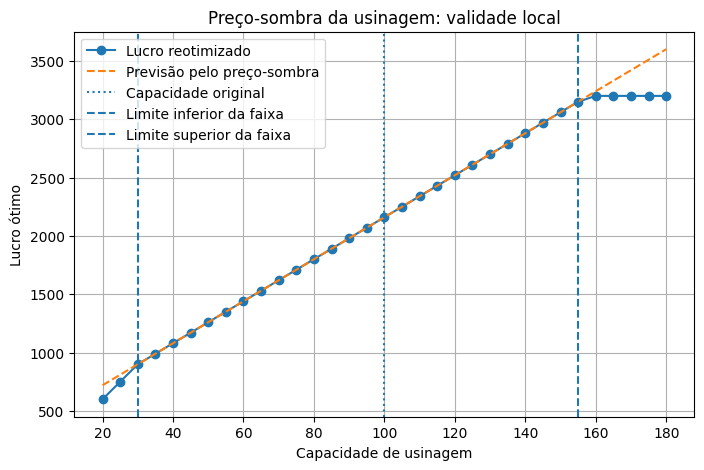

In [52]:
plt.figure(figsize=(8, 5))
plt.plot(df_b1["b1_usinagem"], df_b1["lucro_reotimizado"], marker="o", label="Lucro reotimizado")
plt.plot(df_b1["b1_usinagem"], df_b1["lucro_previsto_preco_sombra"], linestyle="--", label="Previsão pelo preço-sombra")
plt.axvline(100, linestyle=":", label="Capacidade original")
plt.axvline(30, linestyle="--", label="Limite inferior da faixa")
plt.axvline(155, linestyle="--", label="Limite superior da faixa")
plt.xlabel("Capacidade de usinagem")
plt.ylabel("Lucro ótimo")
plt.title("Preço-sombra da usinagem: validade local")
plt.legend()
plt.grid(True)
plt.show()


## Analisando os resultados da Usinagem
Comparamos duas coisas diferentes:

1. **Lucro reotimizado**: resolve novamente o problema para cada novo valor de $b_1$.
2. **Lucro previsto pelo preço-sombra**: usa a aproximação linear:

$$
z(b_1) \approx z_0 + p_1(b_1-b_1^0)
$$

No caso:

$$
z(b_1) \approx 2160 + 18(b_1 - 100)$$

Essa relação é válida **somente dentro da faixa de validade da usinagem**:

$$
30 \leq b_1 \leq 155
$$

conforme apresentado nos slides da aula de análise de sensibilidade.

---

## O que o gráfico está mostrando

No gráfico, a linha azul representa o **lucro reotimizado**, isto é, o lucro ótimo obtido resolvendo novamente o modelo para cada valor de $b_1$.

A linha laranja tracejada representa o **lucro previsto pelo preço-sombra**, calculado por:

```python
lucro_base + precos_sombra["Usinagem"] * (b1 - capacidade["Usinagem"])
```

Como:

```python
lucro_base = 2160
precos_sombra["Usinagem"] = 18
capacidade["Usinagem"] = 100
```

temos:

```python
2160 + 18 * (b1 - 100)
```

---

## Dentro da faixa, os dois lucros coincidem

Observe que para:

$$
30 \leq b_1 \leq 155
$$

o lucro reotimizado e o lucro previsto pelo preço-sombra são iguais.

Por exemplo:

| $b_1$ | Lucro reotimizado | Lucro previsto |
| ----: | ----------------: | -------------: |
|    80 |              1800 |           1800 |
|   100 |              2160 |           2160 |
|   120 |              2520 |           2520 |
|   140 |              2880 |           2880 |

Isso mostra que o preço-sombra $p_1=18$ continua válido nesse intervalo.

A interpretação é:

> Dentro da faixa de validade, cada unidade adicional de usinagem aumenta o lucro ótimo em R$ 18.

---

## Mas a solução $x_A$ e $x_B$ muda

Mesmo dentro da faixa, os valores de $x_A$ e $x_B$ mudam.

Por exemplo:

| $b_1$ | $x_A$ | $x_B$ | Lucro |
| ----: | ----: | ----: | ----: |
|    80 |    30 |    20 |  1800 |
|   100 |    42 |    16 |  2160 |
|   120 |    54 |    12 |  2520 |
|   140 |    66 |     8 |  2880 |

Portanto, a decisão numérica não permanece igual a:

$$
x^* = (42,16)
$$

O que permanece igual é a **base ótima**, isto é, a mesma estrutura de restrições ativas.

---

## Por isso a coluna `mesma_solucao_numerica` aparece como `False`

Calculamos:

```python
"mesma_solucao_numerica": (
    abs(sol["xA"] - x_base["A"]) < 1e-6 and
    abs(sol["xB"] - x_base["B"]) < 1e-6
)
```

Esse teste verifica se:

$
x_A = 42
$

e

$
x_B = 16
$

Ou seja, ele testa se a **solução numérica é exatamente igual à solução base**.

Por isso só aparece `True` quando:

$
b_1 = 100
$

Nos outros valores, mesmo dentro da faixa de validade, aparece `False`, porque $x_A$ e $x_B$ mudam.

---

## 20. Testando as faixas de validade dos recursos

As faixas de validade discutidas na aula são:

| Recurso | Faixa de validade |
|---|---:|
| Usinagem | $30 \leq b_1 \leq 155$ |
| Montagem | $b_2 \geq 58$ |
| Matéria-prima | $50 \leq b_3 \leq 200$ |

Na célula seguinte, vamos variar cada recurso e observar se a solução continua igual à solução base.


In [53]:
def testar_variacao_recurso(recurso, valores):
    linhas = []

    for valor in valores:
        cap_mod = capacidade.copy()
        cap_mod[recurso] = valor

        sol = resolver_cenario(capacidade_modificada=cap_mod)

        linhas.append({
            "Recurso alterado": recurso,
            "Novo valor": valor,
            "xA": round(sol["xA"],1),
            "xB": round(sol["xB"],1),
            "Lucro": sol["lucro"],
            "Mesma solucao numerica": (
                abs(sol["xA"] - x_base["A"]) < 1e-6 and
                abs(sol["xB"] - x_base["B"]) < 1e-6
            )
        })

    return pd.DataFrame(linhas)

df_recursos_teste = pd.concat([
    testar_variacao_recurso("Usinagem", range(20, 181, 20)),
    testar_variacao_recurso("Montagem", range(40, 121, 10)),
    testar_variacao_recurso("Materia_prima", range(30, 231, 20))
], ignore_index=True)

display(df_recursos_teste)


,Recurso alterado,Novo valor,xA,xB,Lucro,Mesma solucao numerica
0,Usinagem,20,0.0,20.0,600.0,False
1,Usinagem,40,6.0,28.0,1080.0,False
2,Usinagem,60,18.0,24.0,1440.0,False
3,Usinagem,80,30.0,20.0,1800.0,False
4,Usinagem,100,42.0,16.0,2160.0,True
5,Usinagem,120,54.0,12.0,2520.0,False
6,Usinagem,140,66.0,8.0,2880.0,False
7,Usinagem,160,80.0,0.0,3200.0,False
8,Usinagem,180,80.0,0.0,3200.0,False
9,Montagem,40,40.0,0.0,1600.0,False


# Parte V — Análise de sensibilidade dos coeficientes da função objetivo

Agora vamos analisar mudanças nos lucros unitários dos produtos.

A função objetivo primal é:

$$
\max z = c_A x_A + c_B x_B
$$

Na solução base:

$$
c_A = 40
$$

$$
c_B = 30
$$

A análise de sensibilidade dos coeficientes da função objetivo responde:

> Se o lucro unitário de um produto mudar, o plano ótimo de produção continua o mesmo?

Nas aulas, as faixas apresentadas foram:

$$
10 < c_A \leq 60
$$

$$
20 \leq c_B < 120
$$

Dentro dessas faixas, a decisão ótima continua sendo:

$$
x_A^* = 42,\quad x_B^* = 16
$$


## 21. Variando o lucro unitário do Produto A

Vamos alterar $c_A$, mantendo $c_B = 30$.
Lembre-se que temos $10 < c_A \leq 60$.

Para cada valor de $c_A$, vamos:

1. resolver novamente o modelo;
2. registrar a nova solução;
3. verificar se a decisão ótima continua igual à solução base.


In [54]:
valores_cA = list(range(5, 81, 5))

linhas = []

for cA in valores_cA:
    lucro_mod = lucro.copy()
    lucro_mod["A"] = cA

    sol = resolver_cenario(
        capacidade_modificada=capacidade,
        lucro_modificado=lucro_mod
    )

    linhas.append({
        "cA_lucro_produto_A": cA,
        "xA": sol["xA"],
        "xB": sol["xB"],
        "lucro": sol["lucro"],
        "mesma_decisao_base": (
            abs(sol["xA"] - x_base["A"]) < 1e-6 and
            abs(sol["xB"] - x_base["B"]) < 1e-6
        )
    })

df_cA = pd.DataFrame(linhas)
display(df_cA)


,cA_lucro_produto_A,xA,xB,lucro,mesma_decisao_base
0,5,0.0,30.0,900.0,False
1,10,0.0,30.0,900.0,False
2,15,42.0,16.0,1110.0,True
3,20,42.0,16.0,1320.0,True
4,25,42.0,16.0,1530.0,True
5,30,42.0,16.0,1740.0,True
6,35,42.0,16.0,1950.0,True
7,40,42.0,16.0,2160.0,True
8,45,42.0,16.0,2370.0,True
9,50,42.0,16.0,2580.0,True


## 22. Gráfico da variação de \(c_A\)

O gráfico mostra como as quantidades ótimas mudam quando alteramos o lucro unitário do Produto A.

As linhas verticais indicam a faixa de validade:

$$
10 \leq c_A \leq 60
$$

Dentro dessa faixa, a solução ótima permanece igual à solução base.


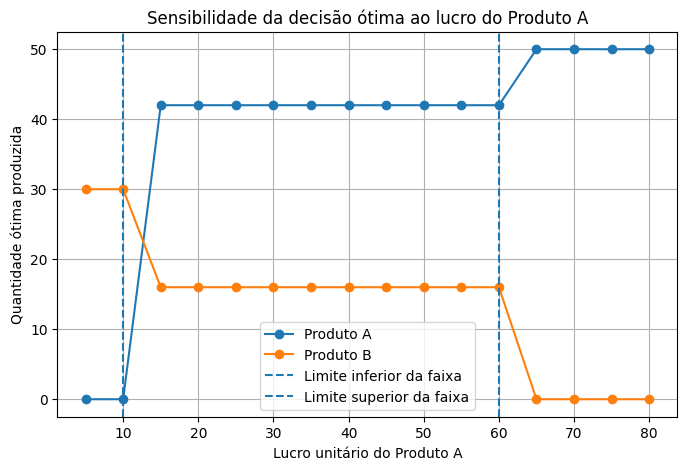

In [55]:
plt.figure(figsize=(8, 5))
plt.plot(df_cA["cA_lucro_produto_A"], df_cA["xA"], marker="o", label="Produto A")
plt.plot(df_cA["cA_lucro_produto_A"], df_cA["xB"], marker="o", label="Produto B")
plt.axvline(10, linestyle="--", label="Limite inferior da faixa")
plt.axvline(60, linestyle="--", label="Limite superior da faixa")
plt.xlabel("Lucro unitário do Produto A")
plt.ylabel("Quantidade ótima produzida")
plt.title("Sensibilidade da decisão ótima ao lucro do Produto A")
plt.legend()
plt.grid(True)
plt.show()


## 23. Variando o lucro unitário do Produto B

Agora vamos alterar $c_B$, mantendo $c_A = 40$.

A faixa de validade apresentada na aula é:

$$
20 \leq c_B < 120
$$


In [56]:
valores_cB = list(range(5, 141, 5))

linhas = []

for cB in valores_cB:
    lucro_mod = lucro.copy()
    lucro_mod["B"] = cB

    sol = resolver_cenario(
        capacidade_modificada=capacidade,
        lucro_modificado=lucro_mod
    )

    linhas.append({
        "cB_lucro_produto_B": cB,
        "xA": sol["xA"],
        "xB": sol["xB"],
        "lucro": sol["lucro"],
        "mesma_decisao_base": (
            abs(sol["xA"] - x_base["A"]) < 1e-6 and
            abs(sol["xB"] - x_base["B"]) < 1e-6
        )
    })

df_cB = pd.DataFrame(linhas)
display(df_cB)


,cB_lucro_produto_B,xA,xB,lucro,mesma_decisao_base
0,5,50.0,0.0,2000.0,False
1,10,50.0,0.0,2000.0,False
2,15,50.0,0.0,2000.0,False
3,20,42.0,16.0,2000.0,True
4,25,42.0,16.0,2080.0,True
5,30,42.0,16.0,2160.0,True
6,35,42.0,16.0,2240.0,True
7,40,42.0,16.0,2320.0,True
8,45,42.0,16.0,2400.0,True
9,50,42.0,16.0,2480.0,True


## 24. Gráfico da variação de \(c_B\)

O gráfico mostra como a decisão ótima muda quando alteramos o lucro unitário do Produto B.

As linhas verticais indicam a faixa de validade:

$$
20 \leq c_B \leq 120
$$


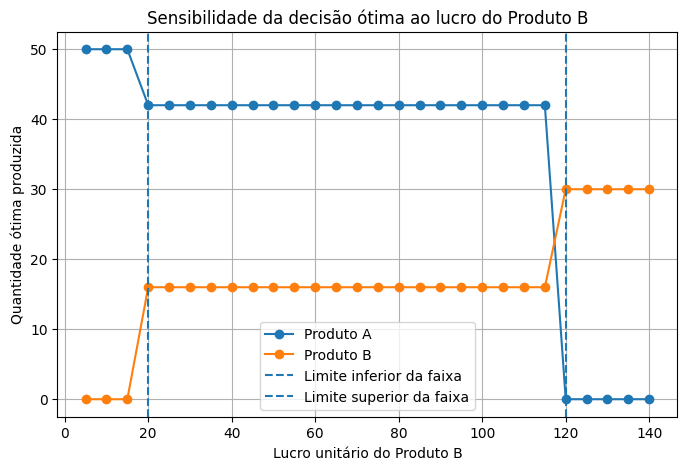

In [57]:
plt.figure(figsize=(8, 5))
plt.plot(df_cB["cB_lucro_produto_B"], df_cB["xA"], marker="o", label="Produto A")
plt.plot(df_cB["cB_lucro_produto_B"], df_cB["xB"], marker="o", label="Produto B")
plt.axvline(20, linestyle="--", label="Limite inferior da faixa")
plt.axvline(120, linestyle="--", label="Limite superior da faixa")
plt.xlabel("Lucro unitário do Produto B")
plt.ylabel("Quantidade ótima produzida")
plt.title("Sensibilidade da decisão ótima ao lucro do Produto B")
plt.legend()
plt.grid(True)
plt.show()


# Parte VI — Exercícios guiados

Resolva os exercícios abaixo modificando os códigos anteriores.

## Exercício 1 — Recurso mais crítico

A empresa pode aumentar apenas um recurso em 10 unidades.

1. Qual recurso você escolheria?
2. Qual ganho aproximado você espera usando preço-sombra?
3. Resolva o modelo com essa nova capacidade e compare o ganho previsto com o ganho real.

## Exercício 2 — Recurso com folga

A capacidade de montagem aumenta de 80 para 100.

1. O lucro muda?
2. A produção ótima muda?
3. Por que isso acontece?

## Exercício 3 — Validade local

A capacidade de usinagem aumenta de 100 para 170.

1. O preço-sombra original ainda prevê corretamente o novo lucro?
2. O que mudou na solução?
3. Por que a análise de sensibilidade é chamada de análise local?

## Exercício 4 — Mudança no lucro

O lucro unitário do Produto A cai de R$ 40 para R$ 8.

1. A produção ótima continua a mesma?
2. Esse valor está dentro ou fora da faixa de sensibilidade?
3. O que o modelo recomenda agora?


## 25. Espaço para resolução dos exercícios

Use as funções já criadas neste notebook:

```python
resolver_cenario(...)
testar_variacao_recurso(...)
```

Você pode alterar os dicionários `capacidade` e `lucro` usando cópias, como nos exemplos anteriores.


In [ ]:
# Exercício 1
# Complete o código a seguir.

# Exemplo:
# cap_mod = capacidade.copy()
# cap_mod["Usinagem"] = capacidade["Usinagem"] + 10
# sol = resolver_cenario(capacidade_modificada=cap_mod)
# sol


In [ ]:
# Exercício 2
# Teste o aumento da capacidade de montagem de 80 para 100.


In [ ]:
# Exercício 3
# Teste o aumento da capacidade de usinagem de 100 para 170.


In [ ]:
# Exercício 4
# Teste a redução do lucro unitário do Produto A de 40 para 8.


# Conclusões da prática

Nesta prática, usamos Pyomo para mostrar que um modelo de programação linear fornece mais do que a solução ótima.

Aprendemos que:

1. a solução primal indica o melhor plano de produção;
2. as folgas indicam quais recursos estão totalmente utilizados;
3. o dual fornece os preços-sombra dos recursos;
4. preço-sombra positivo indica recurso economicamente valioso no ótimo atual;
5. preço-sombra zero indica que uma unidade extra do recurso não melhora o lucro no ótimo atual;
6. a análise de sensibilidade das restrições estuda mudanças nas capacidades dos recursos;
7. a análise de sensibilidade da função objetivo estuda mudanças nos lucros unitários;
8. a validade dos preços-sombra e da solução ótima é local;
9. fora das faixas de validade, o modelo deve ser resolvido novamente.

Mensagem final:

> O modelo ótimo responde "o que fazer agora".  
> A análise de sensibilidade ajuda a responder "e se o cenário mudar?".
